<a href="https://colab.research.google.com/github/aziz-belloumi/AI_testing/blob/MNIST/MNISTClassification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.optim import Adam

# Visualization tools
import torchvision
import torchvision.transforms.v2 as transforms
import torchvision.transforms.functional as F
import matplotlib.pyplot as plt

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.cuda.is_available()

False

In [3]:
train_set = torchvision.datasets.MNIST(root='./data/', train = True , download = True)
valid_set = torchvision.datasets.MNIST(root='./data/', train = False , download = True)

100%|██████████| 9.91M/9.91M [00:01<00:00, 6.07MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 160kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.52MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 5.20MB/s]


In [7]:
train_set

Dataset MNIST
    Number of datapoints: 60000
    Root location: ./data/
    Split: Train

In [8]:
valid_set

Dataset MNIST
    Number of datapoints: 10000
    Root location: ./data/
    Split: Test

In [11]:
x_0, y_0 = train_set[0]

In [21]:
x_0

In [14]:
type(x_0)

PIL.Image.Image

In [13]:
y_0

5

In [15]:
type(y_0)

int

In [16]:
trans = transforms.Compose([transforms.ToTensor()]) # the function responsible for converting a PIL image to a tensor
x_0_tensor = trans(x_0)

/usr/local/lib/python3.11/dist-packages/torchvision/transforms/v2/_deprecated.py:42: UserWarning: The transform `ToTensor()` is deprecated and will be removed in a future release. Instead, please use `v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])`.Output is equivalent up to float precision.
  warnings.warn(


In [17]:
x_0_tensor.dtype

torch.float32

In [18]:
x_0_tensor.min()

tensor(0.)

In [19]:
x_0_tensor.max()

tensor(1.)

In [22]:
x_0_tensor.size()

torch.Size([1, 28, 28])

In [23]:
x_0_tensor

tensor([[[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,

In [25]:
x_0_tensor.device # by default the tensor is processed by a CPU

device(type='cpu')

In [53]:
x_0_gpu = x_0_tensor.cuda() # send the tensor to the GPU
x_0_gpu.device
# in our case it's impossible because cuda is not available right now

RuntimeError: Found no NVIDIA driver on your system. Please check that you have an NVIDIA GPU and installed a driver from http://www.nvidia.com/Download/index.aspx

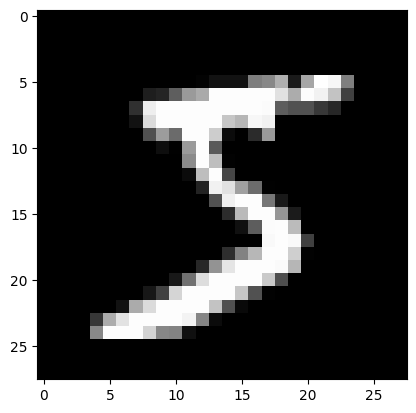

In [27]:
image = F.to_pil_image(x_0_tensor) # to convert a tensor back to a PIL image
plt.imshow(image, cmap='gray')

In [28]:
# after these tests in the properties of the tensors and the PIL images ,
# we need to apply the transformation from the PIL images to tensors in the bothe datasets (train and valid)

train_set.transform = trans
valid_set.transform = trans

In [29]:
batch_size = 32

train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
valid_loader = DataLoader(valid_set, batch_size=batch_size, shuffle=False)

In [30]:
layers = [
    nn.Flatten() , # flatten the tensor to convert it from n-dim to 1-dim
    nn.Linear(in_features=28*28, out_features=512), # this is the input layer and it should has 28*28 neurons as entry due to the size of one image
    nn.ReLU(), # this is the activation function for the input layer (linear)
    nn.Linear(in_features=512, out_features=512), # this is the hidden layer , in this example it kept the same number of neurons as output
    nn.ReLU(), # this is the activation function for the hidden layer
    nn.Linear(512 , 10) # we need ten different classes as output because we have ten numbers to classify
]
layers

[Flatten(start_dim=1, end_dim=-1),
 Linear(in_features=784, out_features=512, bias=True),
 ReLU(),
 Linear(in_features=512, out_features=512, bias=True),
 ReLU(),
 Linear(in_features=512, out_features=10, bias=True)]

In [39]:
# A Sequential model expects a sequence of arguments, not a list,
# so we can use the * operator to unpack our list of layers into a sequence.
model = nn.Sequential(*layers)
model

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=512, bias=True)
  (2): ReLU()
  (3): Linear(in_features=512, out_features=512, bias=True)
  (4): ReLU()
  (5): Linear(in_features=512, out_features=10, bias=True)
)

In [40]:
model.to(device) # like the tensor the model will be processed by default in the CPU

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=512, bias=True)
  (2): ReLU()
  (3): Linear(in_features=512, out_features=512, bias=True)
  (4): ReLU()
  (5): Linear(in_features=512, out_features=10, bias=True)
)

In [41]:
next(model.parameters()).device # to check wich device the model is on

device(type='cpu')

In [42]:
model = torch.compile(model)
# This line is used in PyTorch 2.0+ to enable Just-In-Time (JIT) compilation for your model.
# Its purpose is to make your model run faster by optimizing the underlying computations.

In [44]:
# this function is designed to grade if a model predictedthe correct category from a group of categories !!!!
loss_function = nn.CrossEntropyLoss()

In [45]:
# if the loss_function provides a grade , the optimizer tells the model how to learn from that grade to do better next time
optimizer = Adam(model.parameters())

In [46]:
# calculating accuracy
# While the results of the loss function are effective in helping our model learn,
# the values can be difficult to interpret for humans.
# This is why data scientists often include other metrics like accuracy.
# In order to accurately calculate accuracy, we should compare the number of correct classifications compared to the total number of predictions made.
# Since we're showing data to the model in batches, our accuracy can be calculated along with these batches.
# First, the total number of predictions is the same size as our dataset.
# Let's assign the size of our datasets to `N` where `n` is synonymous with the `batch size`.

train_N = len(train_loader.dataset)
valid_N = len(valid_loader.dataset)

In [47]:
# Next, we'll make a function to calculate the accuracy for each batch.
# The result is a fraction of the total accuracy,
# so we can add the accuracy of each batch together to get the total.

def get_batch_accuracy(output, y, N):
    pred = output.argmax(dim=1, keepdim=True)
    correct = pred.eq(y.view_as(pred)).sum().item()
    return correct / N

In [48]:
# the train function is the assembly of all the previous lines

def train():
    loss = 0
    accuracy = 0

    model.train()
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        output = model(x)
        optimizer.zero_grad()
        batch_loss = loss_function(output, y)
        batch_loss.backward()
        optimizer.step()

        loss += batch_loss.item()
        accuracy += get_batch_accuracy(output, y, train_N)
    print('Train - Loss: {:.4f} Accuracy: {:.4f}'.format(loss, accuracy))

In [49]:
# the validation function

def validate():
    loss = 0
    accuracy = 0

    model.eval()
    with torch.no_grad():
        for x, y in valid_loader:
            x, y = x.to(device), y.to(device)
            output = model(x)

            loss += loss_function(output, y).item()
            accuracy += get_batch_accuracy(output, y, valid_N)
    print('Valid - Loss: {:.4f} Accuracy: {:.4f}'.format(loss, accuracy))

In [50]:
# the training loop

epochs = 5

for epoch in range(epochs):
    print('Epoch: {}'.format(epoch))
    train()
    validate()

Epoch: 0


No CUDA runtime is found, using CUDA_HOME='/usr/local/cuda'


Train - Loss: 376.7278 Accuracy: 0.9389
Valid - Loss: 33.0884 Accuracy: 0.9648
Epoch: 1
Train - Loss: 154.6248 Accuracy: 0.9746
Valid - Loss: 27.4802 Accuracy: 0.9739
Epoch: 2
Train - Loss: 108.7724 Accuracy: 0.9815
Valid - Loss: 27.5157 Accuracy: 0.9729
Epoch: 3
Train - Loss: 81.8754 Accuracy: 0.9856
Valid - Loss: 25.7285 Accuracy: 0.9757
Epoch: 4
Train - Loss: 61.7473 Accuracy: 0.9893
Valid - Loss: 25.8898 Accuracy: 0.9777


In [52]:
prediction = model(x_0_tensor)
prediction

tensor([[-27.5128,  -5.8269, -17.9931,  11.8950, -27.1240,  18.1146, -21.0306,
         -15.1349, -10.4857,  -9.0086]], grad_fn=<CompiledFunctionBackward>)

In [54]:
prediction.argmax(dim=1, keepdim=True)

tensor([[5]])

In [55]:
y_0

5

In [56]:
# Clear the memory !!!
import IPython
app = IPython.Application.instance()
app.kernel.do_shutdown(True)

{'status': 'ok', 'restart': True}